#### Análisis y Procesamiento de Señales

# Tarea Semanal 7 — Filtrado digital lineal de ECG
 **GRUPO 1:** *Del Monaco, García Corona, Miranda, Weitzman.*

## Introducción
Desde el principio de la materia, aprendimos los problemas que nos encontrábamos al tratar con una señal analógica y luego digitalizada. Vimos tratamientos en el dominio de la frecuencia, las consecuencias de esa transformada o periodograma, y sus efectos en el dominio del tiempo. Hoy, después de haber analizado en el trabajo anterior los métodos de filtrado analógico, vamos a introducir los métodos de filtrado digital FIR (Finite Impulse Response) e IIR (Infinite Impulse Response), sus ventajas y desventajas, motivaciones de uso y consideraciones. <br>
En este trabajo los aplicamos a un electrocardiograma (ECG) registrado durante una prueba de esfuerzo y muestreado a $f_s=1kHz$. Por las condiciones en las que se realizó el registro, la señal se encuentra contaminada por distintas fuentes. Nuestro objetivo es mitigar estas interferencias sin deformar el latido, de modo que la señal filtrada se parezca a los latidos promedio.<br>
Como hay interferencias por debajo y por encima de la banda útil del ECG, planteamos un filtro de tipo pasabanda. Primero definimos una plantilla de diseño, declarando los bordes de las bandas de paso y de rechazo, ripple máximo y atenuación mínima, a partir del ancho de banda del ECG que estimamos en la TS5. Con esa misma plantilla diseñamos y comparamos dos familias de filtros:
- Filtros IIR: Implementamos la aproximación de Butterworth, Chebyshev 2 y Cauer. Su ventaja es que cumplen con la plantilla con órdenes bajos. Como desventaja, estos filtros tienen una fase no lineal, lo que distorsiona la forma de la onda. Para compensarlo los aplicamos con `sosfiltfilt` de SciPy que devuelve la señal con fase nula. Esto implica que en las bandas de paso y rechazo las atenuaciones se duplican en dB.
- Filtros FIR: Los diseñamos a partir de tres métodos: Ventanas, cuadrados mínimos y Parks-McClellan-Remez. Son siempre estables y a diferencia de los IIR, pueden tener fase lineal, es decir, todas las componentes de la señal se retrasan lo mismo y la forma de la onda no se distorisona. La desventaja es que necesitamos órdenes mucho mayores para cumplir la misma plantilla.

&nbsp;

Implementamos todos los filtros con SciPy (`scipy.signal`). Primero verificamos que la respuesta en frecuencia de cada uno cumpla con la plantilla y luego evaluamos su desempeño sobre el ECG en dos tipos de regiones: tramos con interferencias para comprobar que se atenúan y tramos sin interferencias, para comprobar que el filtro no altera la señal.

## Desarrollo
Importamos las librerias que se usan a lo largo del trabajo e importamos el archivo con la información correspondiente al ECG.



In [1]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import scipy.io as sio
import os
import matplotlib.ticker as ticker

url_mat = 'https://github.com/franciscoweitzman-cyber/aps_francisco_weitzman/raw/refs/heads/main/TS7/ECG_TP4.mat'
nombre_archivo = 'ECG_TP4.mat'
os.system(f'wget "{url_mat}" -O {nombre_archivo}')


# =============================================================================
#  Importo de ECG con ruido #
# =============================================================================
fs_ecg = 1000 # Hz
sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')

# _______Vemos qué variables tiene el diccionario________
print("Claves disponibles en el archivo .mat:")
print(mat_struct.keys())
# ________________________________________________________

ecg_one_lead = mat_struct['ecg_lead']
N = len(ecg_one_lead)
ecg_one_lead = (ecg_one_lead*1.0).flatten()
cant_muestras = ecg_one_lead.shape[0]

Claves disponibles en el archivo .mat:
dict_keys(['__header__', '__version__', '__globals__', 'ecg_lead', 'qrs_pattern1', 'heartbeat_pattern1', 'heartbeat_pattern2', 'qrs_detections'])


#### Plantilla de Diseño BW:
Para diseñar la plantilla, usamos los valores medidos en la TS5, que nos daban valores de BW del ECG sin ruido de [0,6Hz;35Hz]. Además, el ruido eléctrico debido a la respiración ocurre alrededor de los 0,5Hz, y el ruido de la línea eléctrica es de 50Hz, pero elegimos un valor menor a 40Hz para evitar problemas, ya que además el ancho de banda del ECG no se cruza con aquel de la línea.

In [2]:
nyq_frec = fs_ecg/2
# frecuencias de paso y corte
ws1 = 0.1    # Hz
wp1 = 1     # Hz
wp2 = 35.0    # Hz
ws2 = 40.0    # Hz
rip = 1.0     # dB ripple (gpass)
ate = 40.0    # dB atenuacion (gstop)

## Filtros IIR

Realizamos los filtros IIR implementando la función `iirdesign` que requiere los parámetros para las bandas de paso y rechazo, el ripple la atenuación, el tipo de filtro, el tipo de salida y la frecuencia de muestreo.

En este caso se realizaron filtros tipo: Butterworth <code>(<font color="#ce9178">'butter'</font>)</code>, Chebyshev 2 <code>(<font color="#ce9178">'cheby2'</font>)</code> y Cauer <code>(<font color="#ce9178">'ellip'</font>)</code>

In [3]:
sos_but = sig.iirdesign([wp1,wp2], [ws1, ws2], gpass=rip, gstop=ate, analog=False, ftype='butter', output='sos', fs=fs_ecg)
sos_ch2 = sig.iirdesign([wp1,wp2], [ws1, ws2], gpass=rip, gstop=ate, analog=False, ftype='cheby2', output='sos', fs=fs_ecg)
sos_ell = sig.iirdesign([wp1,wp2], [ws1, ws2], gpass=rip, gstop=ate, analog=False, ftype='ellip', output='sos', fs=fs_ecg)

## Filtros FIR
Planteamos la base para los filtros FIR. Se define la cantidad de coeficientes del filtro, las frecuencias y ganancias en el formato que lo requiere `firwin2`. Diseñamos los filtros por cuadrados mínimos `(firls)` y por Parks-McClellan `(remez)`

In [4]:
taps_win = 2001
b_firls = sig.firls(numtaps=taps_win,
                    bands=  [0.0, wp1-0.8, wp1-0.1,     wp2, wp2+1.0, nyq_frec],
                    desired=[0.0, 0.0,     1.0,     1.0, 0.0,     0.0],
                    weight= [100.0, 1.0, 1.0],
                    fs=fs_ecg)
dem_firls = (taps_win-1)//2

taps_winr = 2501
b_remez = sig.remez(numtaps=taps_winr,
                    bands=[0.0, wp1-0.8, wp1-0.1, wp2, wp2+1.0, nyq_frec],
                    desired=[0.0, 1.0, 0.0],
                    weight=[5.0, 1.0, 5.0],
                    type='bandpass',
                    maxiter=100,
                    grid_density=64,
                    fs=fs_ecg)
dem_remez = (taps_winr-1)//2

# =============================================================================
# visualizacion en frecuncia del filtro
# =============================================================================

ww = np.concatenate([
    np.logspace(start=np.log10(0.01), stop=np.log10(1.25), num=1000),
    np.linspace(start=1.26, stop=30, num=200),
    np.logspace(start=np.log10(30.1), stop=np.log10(60), num=1000),
    np.linspace(start=60.1, stop=nyq_frec, num=200)
    ])

ww = np.unique(ww) #flatten
ww = ww[ww <= nyq_frec]

w_but, h_but = sig.freqz_sos(sos_but, worN=ww, fs=fs_ecg)
w_ch2, h_ch2 = sig.freqz_sos(sos_ch2, worN=ww, fs=fs_ecg)
w_ell, h_ell = sig.freqz_sos(sos_ell, worN=ww, fs=fs_ecg)
w_fls, h_fls = sig.freqz(b_firls, 1, worN=ww, fs=fs_ecg)
w_rem, h_rem = sig.freqz(b_remez, 1, worN=ww, fs=fs_ecg)


## Gráficos
Se muestra, a continuacion, cada uno de los cinco filtro en modulo y fase en funcion de la frecuencia en eje logaritmico:

/tmp/ipykernel_524/91761921.py:10: RuntimeWarning: divide by zero encountered in log10
  return 20*np.log10(np.abs(h))


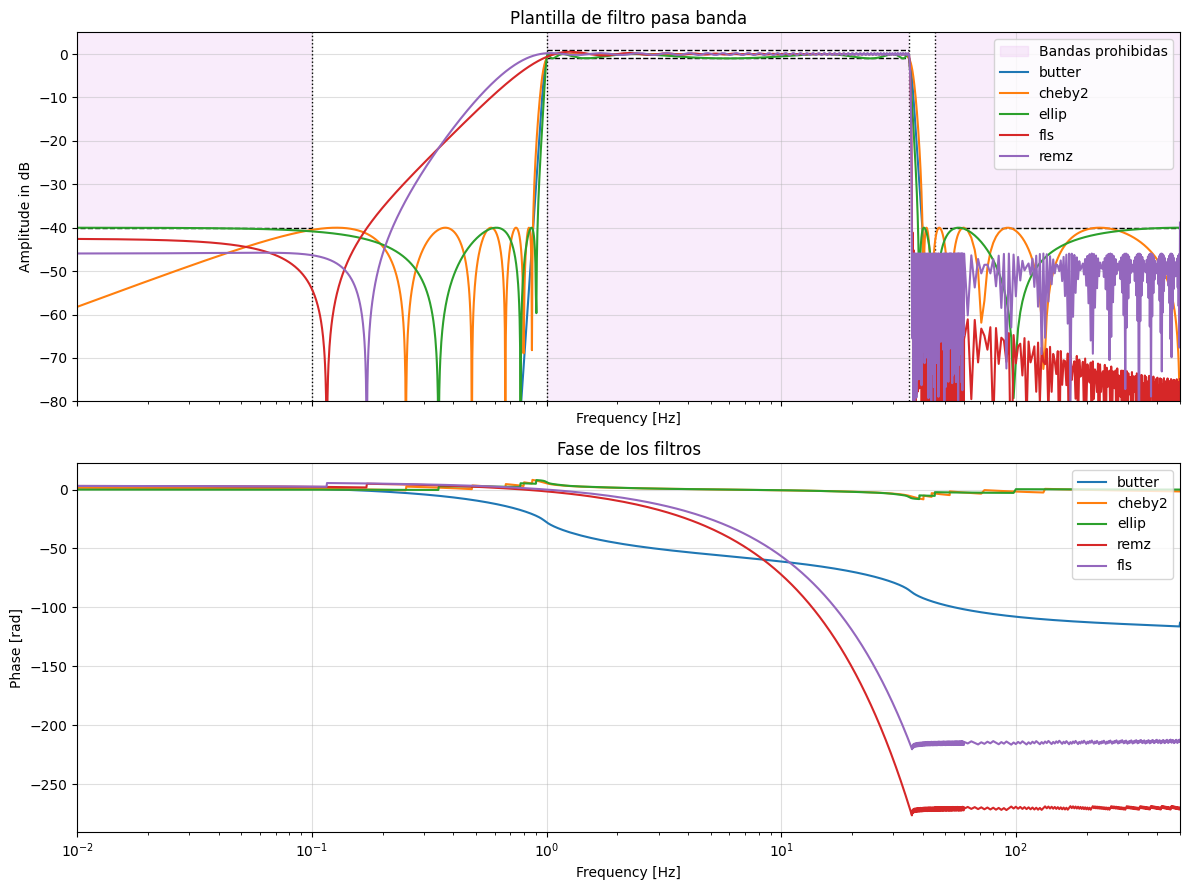

In [5]:
# =============================================================================
# plantilla grafica de diseño del filtro
# =============================================================================
# %%

FMAX, YMIN, YMAX = 500, -80, 5
COLOR = '#e8b4f0'

def a_db(h): #pasa a db la respuesta de amplitud de los filtros para graficarlos
    return 20*np.log10(np.abs(h))

def fase(h): #fase desenrollada de la respuesta en frecuencia (radianes)
    return np.unwrap(np.angle(h))


def dibujar_plantilla(ax, ws1_fig, wp1_fig, wp2_fig, ws2_fig, rip_fig, ate_fig, fmax=FMAX, ymin=YMIN, ymax=YMAX):
    kw = dict(color=COLOR, alpha=0.25, lw=0)
    # Zonas prohibidas
    ax.fill_between([1e-3, ws1_fig],    -ate_fig, ymax, **kw)          # corte inferior
    ax.fill_between([ws2_fig, fmax], -ate_fig, ymax, **kw)             # corte superior
    ax.fill_between([wp1_fig, wp2_fig],  ymin, -rip_fig, **kw)         # paso: debajo de -rip_fig
    ax.fill_between([wp1_fig, wp2_fig],  rip_fig, ymax, **kw)          # paso: encima de +rip_fig
    # Límites
    ax.hlines([rip_fig, -rip_fig], wp1_fig, wp2_fig, colors='k', linestyles='--', lw=1)
    ax.hlines(-ate_fig, ws2_fig, fmax, colors='k', linestyles='--', lw=1)
    ax.hlines(-ate_fig, 1e-3, ws1_fig, colors='k', linestyles='--', lw=1)
    ax.vlines([ws1_fig, wp1_fig, wp2_fig, ws2_fig], ymin, ymax, colors='k', linestyles=':', lw=1)
    # Entrada de leyenda
    ax.fill_between([], [], [], color=COLOR, alpha=0.25, label='Bandas prohibidas')

if __name__ == '__main__':
    fig, (ax, ax_fase) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
    dibujar_plantilla(ax,
                      ws1_fig=0.1,
                      wp1_fig=1,
                      wp2_fig=35,
                      ws2_fig=45,
                      rip_fig=1,
                      ate_fig=40)

    # ax.plot(f, a_db(np.abs(H)), label='Filtro')
    ax.plot(w_but, a_db(h_but), label="butter")
    ax.plot(w_ch2, a_db(h_ch2), label="cheby2")
    ax.plot(w_ell, a_db(h_ell), label="ellip")
    ax.plot(w_fls, a_db(h_fls), label="fls")
    ax.plot(w_rem, a_db(h_rem), label="remz")

    ax.set_xscale('log')
    ax.set_xlim(0.01, FMAX)
    ax.set_ylim(YMIN, YMAX)
    ax.set_xlabel('Frequency [Hz]')
    ax.set_ylabel('Amplitude in dB')
    ax.set_title('Plantilla de filtro pasa banda')
    ax.grid(True, alpha=0.4)
    ax.legend(loc='upper right')

    # --- Fase (mismo orden y mismas etiquetas que arriba) ---
    ax_fase.plot(w_but, fase(h_but), label="butter")
    ax_fase.plot(w_ch2, fase(h_ch2), label="cheby2")
    ax_fase.plot(w_ell, fase(h_ell), label="ellip")
    ax_fase.plot(w_rem, fase(h_rem), label="remz")
    ax_fase.plot(w_fls, fase(h_fls), label="fls")

    ax_fase.set_xlabel('Frequency [Hz]')
    ax_fase.set_ylabel('Phase [rad]')
    ax_fase.set_title('Fase de los filtros')
    ax_fase.grid(True, alpha=0.4)
    ax_fase.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

Se observa que los filtros IIR diseñados tienen distorsión de fase en la banda de interes, mientras que los FIR tienen fase lineal (se ven como curvas por que el eje de frecuencia esta logaritmado). Se observa que los filtros FIR tienen una transicion mas corta en la frecuencias de corte altas.  

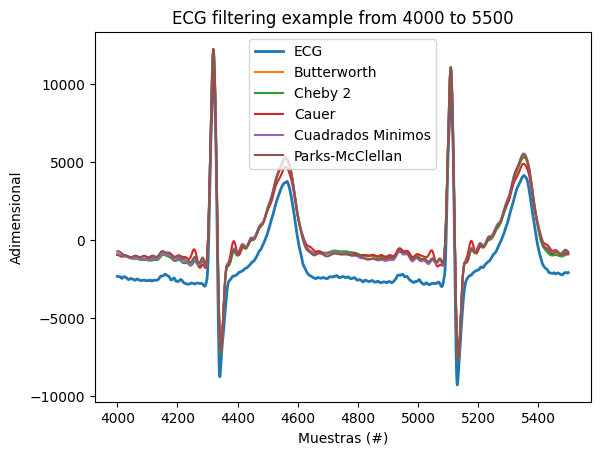

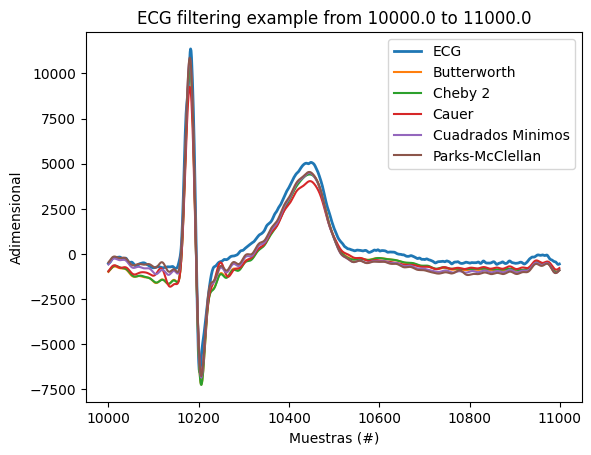

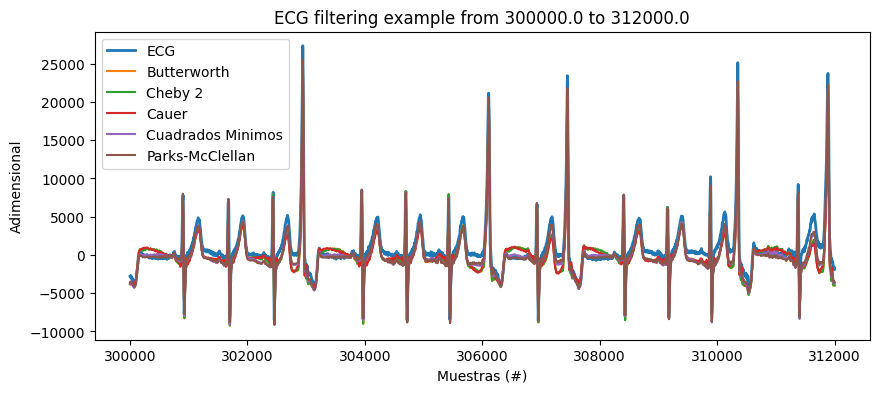

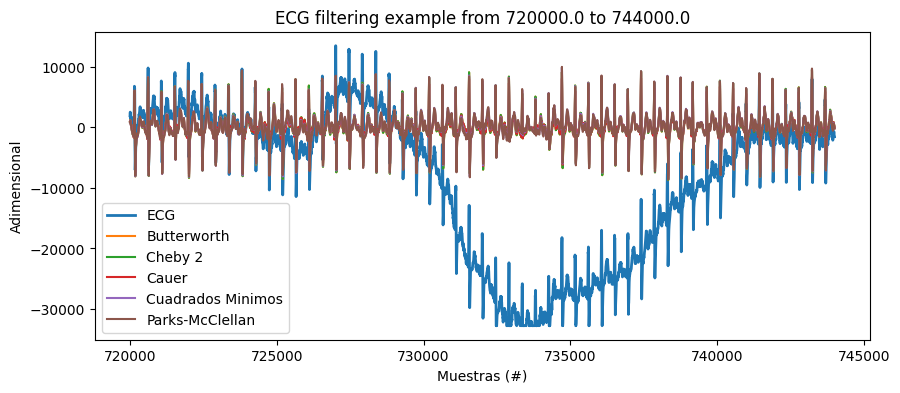

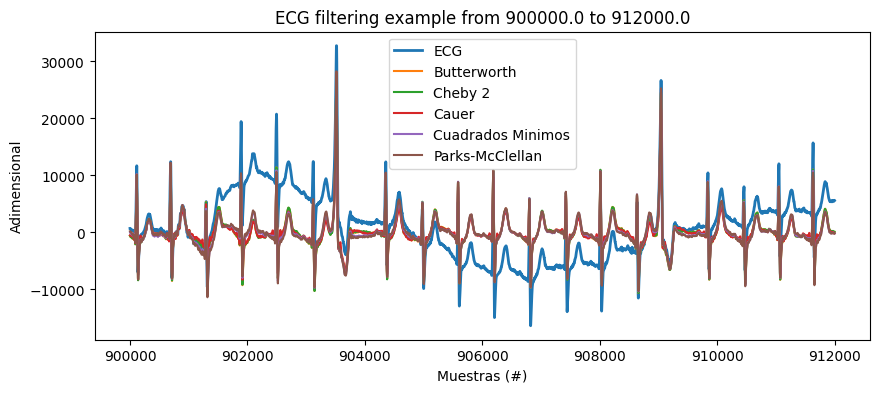

In [6]:
# =============================================================================
# aplicacion del filtro
# =============================================================================
# %%

ecg_but = sig.sosfiltfilt(sos_but, ecg_one_lead)
ecg_ch2 = sig.sosfiltfilt(sos_ch2, ecg_one_lead)
ecg_ell = sig.sosfiltfilt(sos_ell, ecg_one_lead)
ecg_fls = sig.lfilter(b_firls, 1, ecg_one_lead)
ecg_rem = sig.lfilter(b_remez, 1, ecg_one_lead)


# =============================================================================
# Regiones de interés con ruido
# =============================================================================
# %%
cant_muestras = ecg_one_lead.shape[0]

regs_interes = (
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    plt.figure()
    plt.plot(zoom_region, ecg_one_lead[zoom_region],        label='ECG', linewidth=2)
    plt.plot(zoom_region, ecg_but[zoom_region],             label='Butterworth')
    plt.plot(zoom_region, ecg_ch2[zoom_region],             label='Cheby 2')
    plt.plot(zoom_region, ecg_ell[zoom_region],             label='Cauer')
    plt.plot(zoom_region, ecg_fls[zoom_region + dem_firls],   label='Cuadrados Minimos')
    plt.plot(zoom_region, ecg_rem[zoom_region + dem_remez],   label='Parks-McClellan')

    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()

    plt.show()

# =============================================================================
# Regiones de interés sin ruido #
# =============================================================================

regs_interes = (
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras
        np.array([15, 15.2]) *60*fs_ecg, # minutos a muestras
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')

    plt.figure(figsize=(10, 4))
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, ecg_but[zoom_region],             label='Butterworth')
    plt.plot(zoom_region, ecg_ch2[zoom_region],             label='Cheby 2')
    plt.plot(zoom_region, ecg_ell[zoom_region],             label='Cauer')
    plt.plot(zoom_region, ecg_fls[zoom_region + dem_firls],   label='Cuadrados Minimos')
    plt.plot(zoom_region, ecg_rem[zoom_region + dem_remez],   label='Parks-McClellan')

    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()

    plt.show()

Hay varias zonas de interes donde se pueden apreciar los efectos de los filtros. Por un lado, en las zonas de 4000 a 5500 y de 10000 a 11000 muestras se observa que los filtros cumplen con el objetivo propuesto y filtran de manera correcta segun su diseño. Las ondulaciones que se observan es estas zonas no son distoricion de fase sino visualizaciones de la respuesta al impulso producto de la naturaleza de la señal, de corto 'rise time', parecida a un impulso. Se puede afirmar que no es distorcion de fase en el caso de los filtros IIR por haber sido aplicados de manera bidireccional. Luego, en la zona de 300000 a 312000 muestras, donde la señal original no tenia interferencias de baja frecuencia, podemos observar que los filtros no realizaron un filtrado destructivo en esta zona de interes. Por ultimo, en 720000 a 744000 y en 900000 a 912000 muestras, se observa el filtrado en bajas frecuencias que logran los cinco filtros.

## Conclusion
Podemos apreciar que todos no todos estos filtros tienen un comportamiento lineal en la banda de paso. Segun su respuesta al impulso, podemos hacer dos grandes observaciones. Por un lado, los filtros IIR tienen fase no lineal, lo que podria generar distorsion de fase al ser utilizados. Por la manera en la fueron aplicados, es decir, de manera bidireccional, este efecto no deseado de distorsion de fase es inocuo. La contra parte de esta aplicacion es que no puede ser realizada en tiempo real. Seguidamente, los filtros FIR son de fase lineal en la banda de paso, algo que afecta al retardo de la señal pero, al tener fase lineal, el retardo va a ser constante, por lo que no generaran distorsion de fase.

Los filtros IIR tienen un menor costo computacional que los FIR, pero su contraparte es que si se los quiere aplicar de manera tal que no generen distorsion de fase, no se los podra aplicar en tiempo real. Por otro lado, los FIR presentan la ventaja de, al tener fase lineal, pueden ser aplicados en tiempo real pero con un mayor costo computacional.


